# Experiment No. 2
## Exploratory Data Analysis (EDA) on a Real-World Business Dataset using Python

**Aim:** To perform Exploratory Data Analysis on a real-world dataset in order to understand its structure, identify trends, detect anomalies, analyze feature relationships, and generate business insights through descriptive statistics and visualizations.

**Dataset:** IBM HR Employee Attrition Dataset (1470 employees, 35 columns)

**Business objective:** Understand which factors influence employee attrition (`Attrition` = Yes/No) so that HR can reduce it.

## Step 1 & 2: Select the dataset, import libraries and load the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100

url = "https://raw.githubusercontent.com/IBM/employee-attrition-aif360/master/data/emp_attrition.csv"
df = pd.read_csv(url, encoding="utf-8-sig")   # or pd.read_csv("WA_Fn-UseC_-HR-Employee-Attrition.csv")
print("Original shape:", df.shape)

Original shape: (1470, 35)


**Basic cleaning (from Experiment 1):** the dataset has no missing values or duplicates. We only drop columns that carry no information (same value for every employee, or just an ID).

In [2]:
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

df = df.drop(columns=["EmployeeCount", "StandardHours", "Over18", "EmployeeNumber"])

# Numeric version of the target, useful for averages and correlations
df["AttritionFlag"] = (df["Attrition"] == "Yes").astype(int)
print("Cleaned shape:", df.shape)

Missing values: 0
Duplicate rows: 0
Cleaned shape: (1470, 32)


## Step 3: Explore the dataset

In [3]:
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EnvironmentSatisfaction,Gender,...,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,AttritionFlag
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,2,Female,...,1,0,8,0,1,6,4,0,5,1
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,3,Male,...,4,1,10,3,3,10,7,1,7,0
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,4,Male,...,2,0,7,3,3,0,0,0,0,1
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,4,Female,...,3,0,8,3,3,8,7,3,0,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,Male,...,4,1,6,3,3,2,2,2,2,0


In [4]:
print("Rows, columns:", df.shape)
print("\nColumn names:\n", df.columns.tolist())
df.info()

Rows, columns: (1470, 32)

Column names:
 ['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department', 'DistanceFromHome', 'Education', 'EducationField', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction', 'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'OverTime', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager', 'AttritionFlag']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 32 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   Da

In [5]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Age,1470.0,36.92,9.14,18.0,30.0,36.0,43.00,60.0
DailyRate,1470.0,802.49,403.51,102.0,465.0,802.0,1157.00,1499.0
DistanceFromHome,1470.0,9.19,8.11,1.0,2.0,7.0,14.00,29.0
Education,1470.0,2.91,1.02,1.0,2.0,3.0,4.00,5.0
EnvironmentSatisfaction,1470.0,2.72,1.09,1.0,2.0,3.0,4.00,4.0
HourlyRate,1470.0,65.89,20.33,30.0,48.0,66.0,83.75,100.0
JobInvolvement,1470.0,2.73,0.71,1.0,2.0,3.0,3.00,4.0
JobLevel,1470.0,2.06,1.11,1.0,1.0,2.0,3.00,5.0
JobSatisfaction,1470.0,2.73,1.10,1.0,2.0,3.0,4.00,4.0
MonthlyIncome,1470.0,6502.93,4707.96,1009.0,2911.0,4919.0,8379.00,19999.0


In [6]:
cat_cols = df.select_dtypes(include="object").columns.tolist()
num_cols = df.select_dtypes(include="number").columns.drop("AttritionFlag").tolist()

for col in cat_cols:
    print(f"--- {col} ---")
    print(df[col].value_counts(), "\n")

--- Attrition ---
Attrition
No     1233
Yes     237
Name: count, dtype: int64 

--- BusinessTravel ---
BusinessTravel
Travel_Rarely        1043
Travel_Frequently     277
Non-Travel            150
Name: count, dtype: int64 

--- Department ---
Department
Research & Development    961
Sales                     446
Human Resources            63
Name: count, dtype: int64 

--- EducationField ---
EducationField
Life Sciences       606
Medical             464
Marketing           159
Technical Degree    132
Other                82
Human Resources      27
Name: count, dtype: int64 

--- Gender ---
Gender
Male      882
Female    588
Name: count, dtype: int64 

--- JobRole ---
JobRole
Sales Executive              326
Research Scientist           292
Laboratory Technician        259
Manufacturing Director       145
Healthcare Representative    131
Manager                      102
Sales Representative          83
Research Director             80
Human Resources               52
Name: count, dtype:

Attrition
No     1233
Yes     237
Name: count, dtype: int64
Attrition
No     83.9
Yes    16.1
Name: proportion, dtype: float64


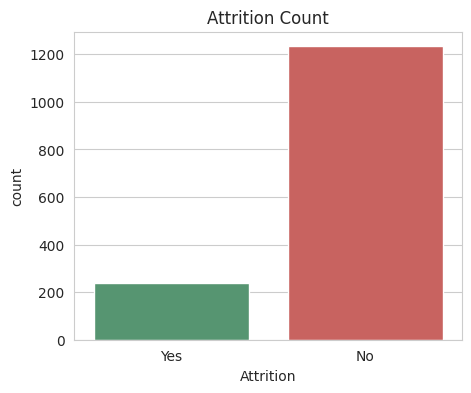

In [7]:
# Target variable and class imbalance
print(df["Attrition"].value_counts())
print((df["Attrition"].value_counts(normalize=True) * 100).round(1))

plt.figure(figsize=(5, 4))
sns.countplot(x="Attrition", data=df, palette=["#4C9F70", "#D9534F"])
plt.title("Attrition Count")
plt.show()

**Observation:** only about 16% of employees left, so the target is imbalanced (about 5 stayers for every leaver).

## Step 4: Distribution of numerical features (histograms and density plots)

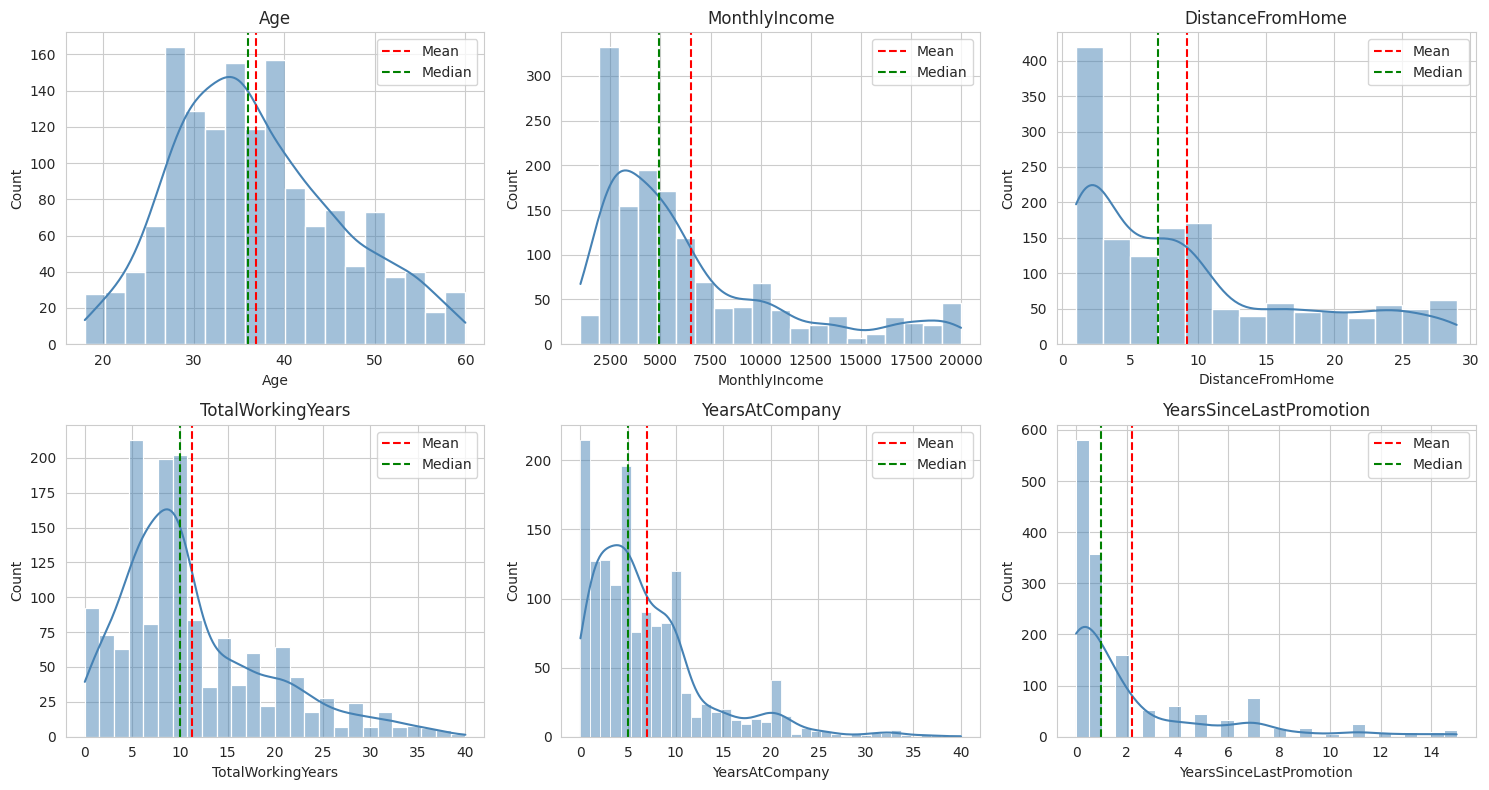

In [8]:
key_num = ["Age", "MonthlyIncome", "DistanceFromHome", "TotalWorkingYears",
           "YearsAtCompany", "YearsSinceLastPromotion"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), key_num):
    sns.histplot(df[col], kde=True, ax=ax, color="steelblue")
    ax.axvline(df[col].mean(), color="red", linestyle="--", label="Mean")
    ax.axvline(df[col].median(), color="green", linestyle="--", label="Median")
    ax.set_title(col)
    ax.legend()
plt.tight_layout()
plt.show()

In [9]:
# Skewness: values far from 0 indicate skewed distributions
df[num_cols].skew().sort_values(ascending=False).round(2).head(10)

,0
YearsSinceLastPromotion,1.98
PerformanceRating,1.92
YearsAtCompany,1.76
MonthlyIncome,1.37
TotalWorkingYears,1.12
NumCompaniesWorked,1.03
JobLevel,1.03
StockOptionLevel,0.97
DistanceFromHome,0.96
YearsInCurrentRole,0.92


**Observation:** Age is roughly bell-shaped (mean about 37). MonthlyIncome, YearsAtCompany, TotalWorkingYears and YearsSinceLastPromotion are right-skewed: the mean is greater than the median because a few employees have very high income or very long tenure.

## Step 5: Categorical variables (bar charts and count plots)

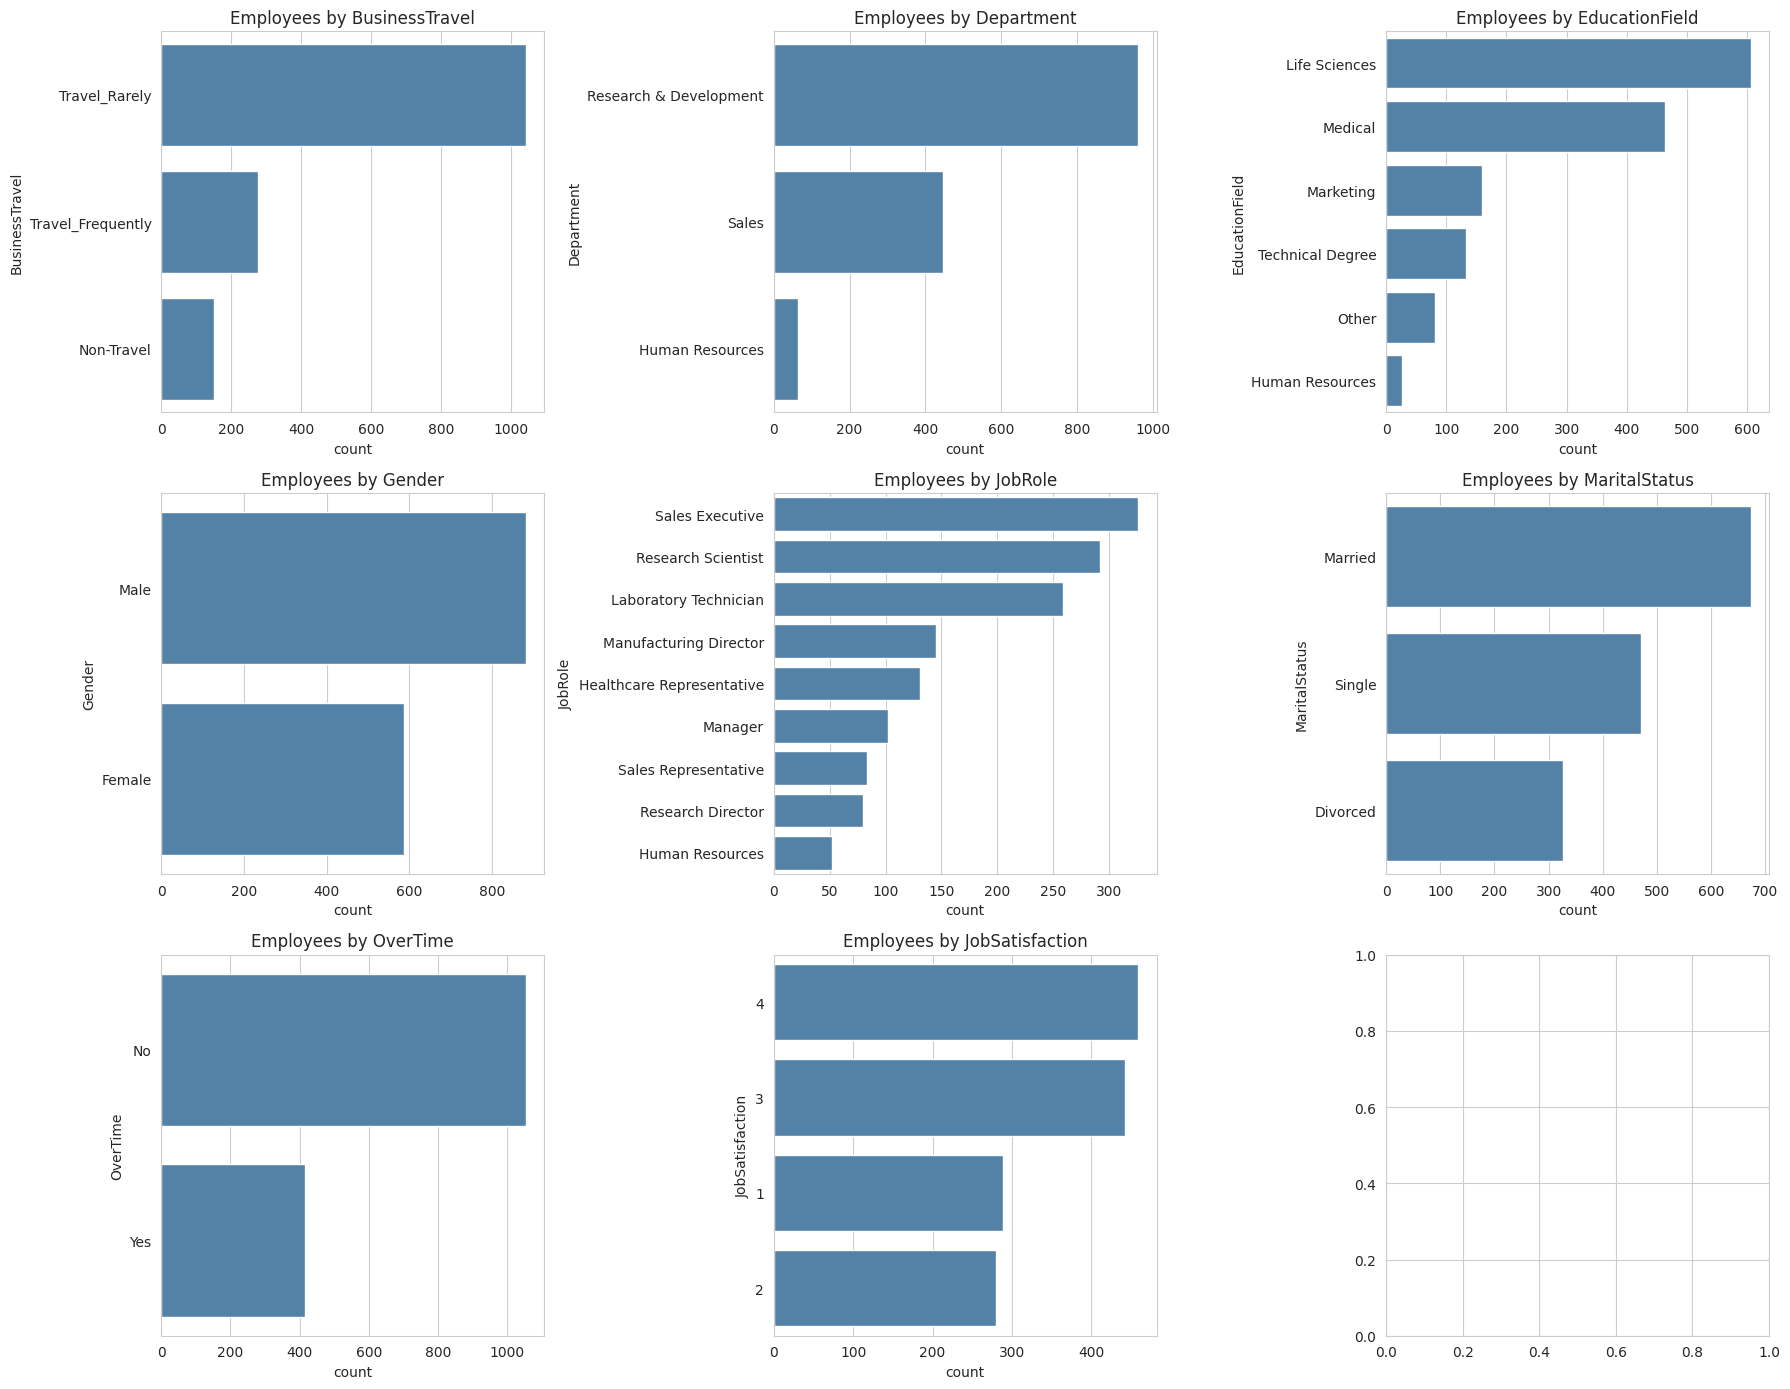

In [10]:
fig, axes = plt.subplots(3, 3, figsize=(18, 14))
for ax, col in zip(axes.ravel(), [c for c in cat_cols if c != "Attrition"] + ["JobSatisfaction"]):
    order = df[col].value_counts().index
    sns.countplot(y=col, data=df, order=order, ax=ax, color="steelblue")
    ax.set_title(f"Employees by {col}")
plt.tight_layout()
plt.show()

**Observation:** Research & Development is the largest department; most employees travel rarely; the most common job roles are Sales Executive, Research Scientist and Laboratory Technician; most are married; about 28% work overtime.

## Step 6: Correlation matrix and heatmap

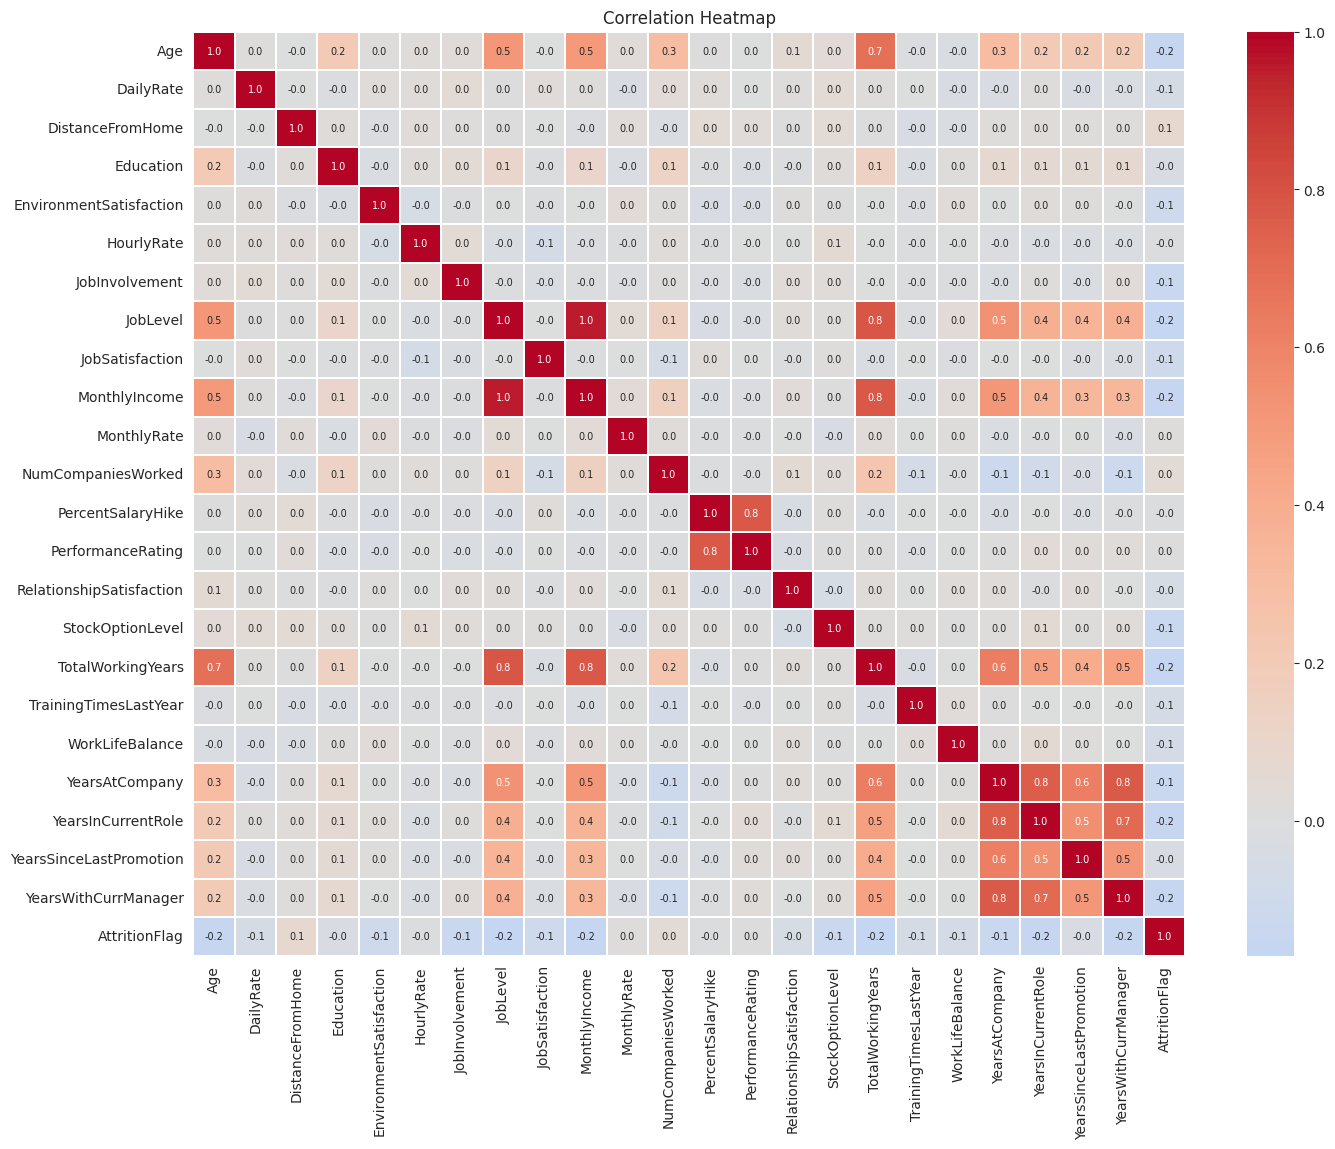

In [11]:
corr = df[num_cols + ["AttritionFlag"]].corr()

plt.figure(figsize=(16, 12))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=True, fmt=".1f",
            annot_kws={"size": 7}, linewidths=0.3)
plt.title("Correlation Heatmap")
plt.show()

In [12]:
# Highly correlated feature pairs (|r| > 0.7)
pairs = corr.abs().unstack().reset_index()
pairs.columns = ["Feature 1", "Feature 2", "|r|"]
pairs = pairs[pairs["Feature 1"] < pairs["Feature 2"]]
pairs[pairs["|r|"] > 0.7].sort_values("|r|", ascending=False).round(2)

,Feature 1,Feature 2,|r|
177,JobLevel,MonthlyIncome,0.95
184,JobLevel,TotalWorkingYears,0.78
301,PercentSalaryHike,PerformanceRating,0.77
232,MonthlyIncome,TotalWorkingYears,0.77
478,YearsAtCompany,YearsWithCurrManager,0.77
476,YearsAtCompany,YearsInCurrentRole,0.76
502,YearsInCurrentRole,YearsWithCurrManager,0.71


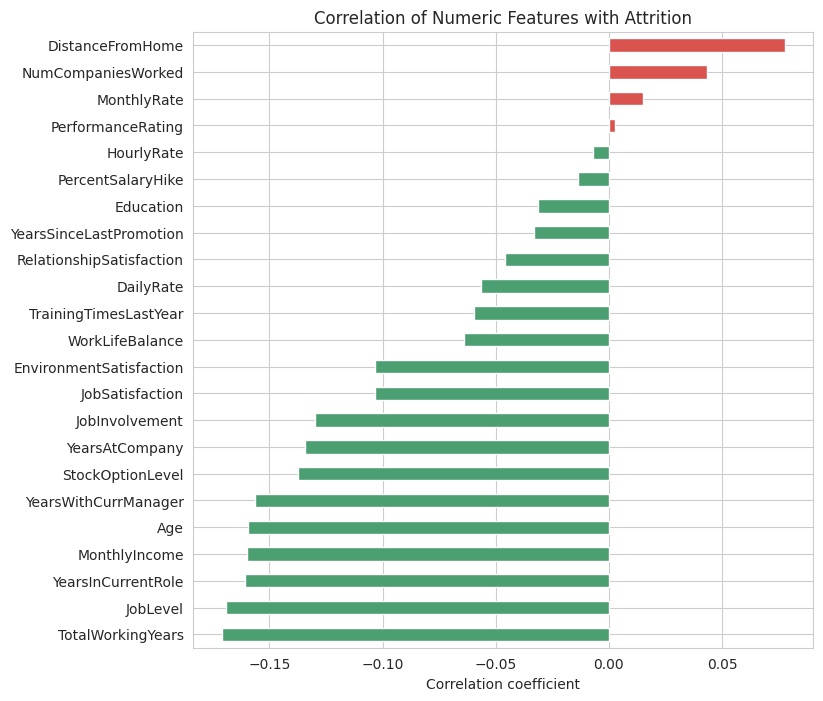

In [13]:
# Correlation of every numeric feature with Attrition
att_corr = corr["AttritionFlag"].drop("AttritionFlag").sort_values()

plt.figure(figsize=(8, 8))
att_corr.plot(kind="barh", color=["#D9534F" if v > 0 else "#4C9F70" for v in att_corr])
plt.title("Correlation of Numeric Features with Attrition")
plt.xlabel("Correlation coefficient")
plt.show()

**Observation:** MonthlyIncome and JobLevel are very strongly correlated (about 0.95), and TotalWorkingYears, JobLevel and MonthlyIncome move together (about 0.77 to 0.78). PerformanceRating and PercentSalaryHike are also correlated (about 0.77), as are YearsAtCompany and YearsWithCurrManager. These pairs are redundant and matter for feature selection. Attrition has only weak individual correlations: it is higher for employees living far away (about +0.08) and lower for employees with more experience, higher level and higher income (about -0.16 to -0.17).

## Step 7: Box plots and scatter plots (outliers and relationships)

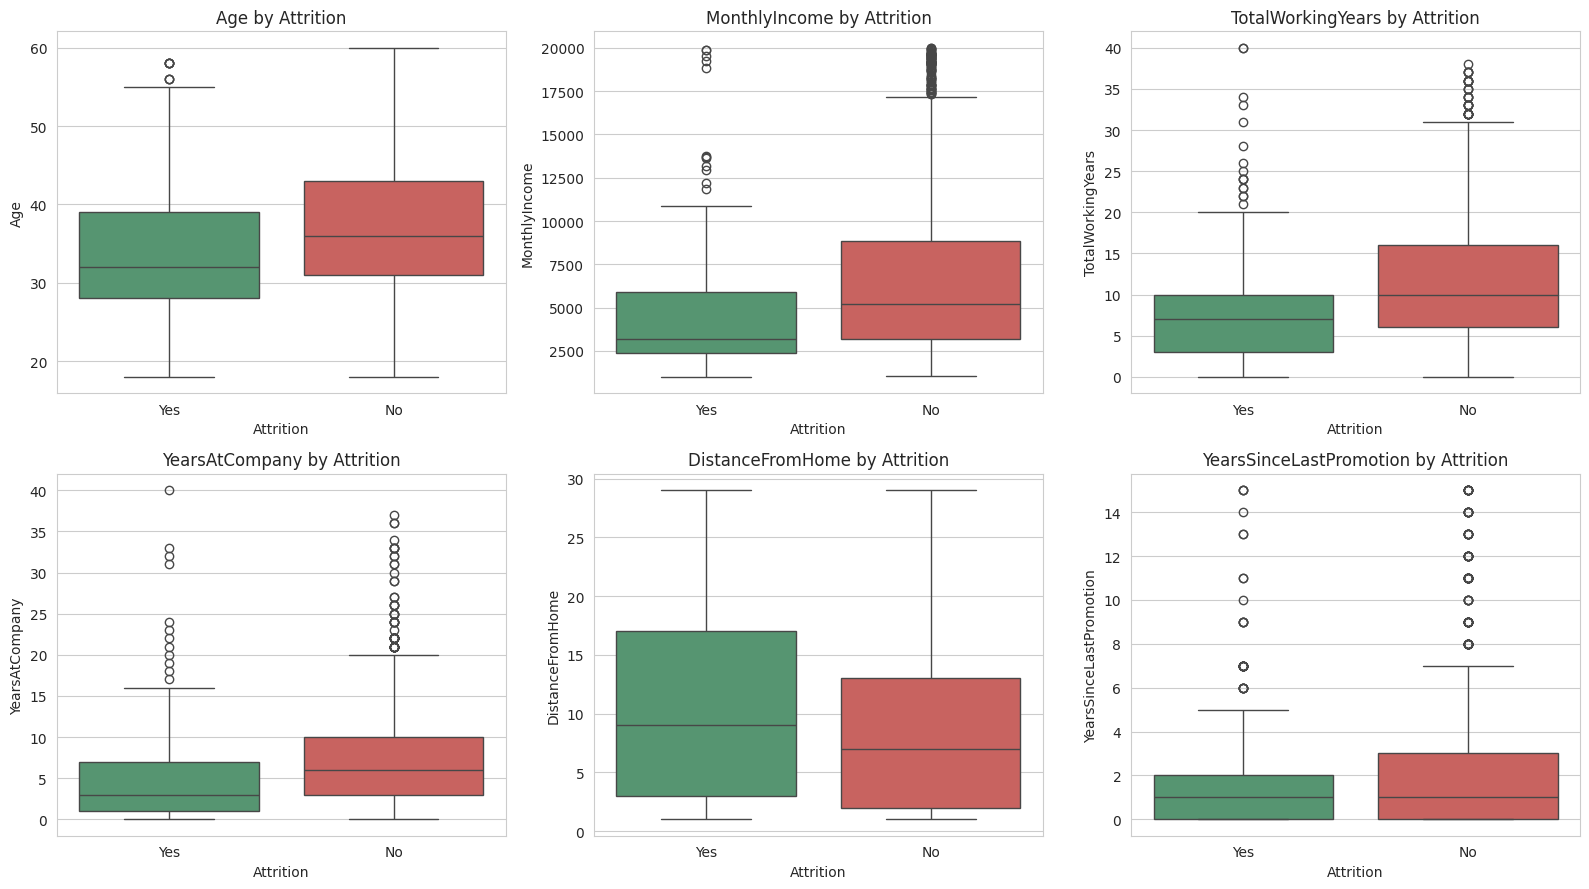

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.ravel(), ["Age", "MonthlyIncome", "TotalWorkingYears",
                                 "YearsAtCompany", "DistanceFromHome", "YearsSinceLastPromotion"]):
    sns.boxplot(x="Attrition", y=col, data=df, ax=ax, palette=["#4C9F70", "#D9534F"])
    ax.set_title(f"{col} by Attrition")
plt.tight_layout()
plt.show()

In [15]:
# Number of IQR outliers per feature
def count_outliers(s):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

out = df[num_cols].apply(count_outliers)
out[out > 0].sort_values(ascending=False)

,0
TrainingTimesLastYear,238
PerformanceRating,226
MonthlyIncome,114
YearsSinceLastPromotion,107
YearsAtCompany,104
StockOptionLevel,85
TotalWorkingYears,63
NumCompaniesWorked,52
YearsInCurrentRole,21
YearsWithCurrManager,14


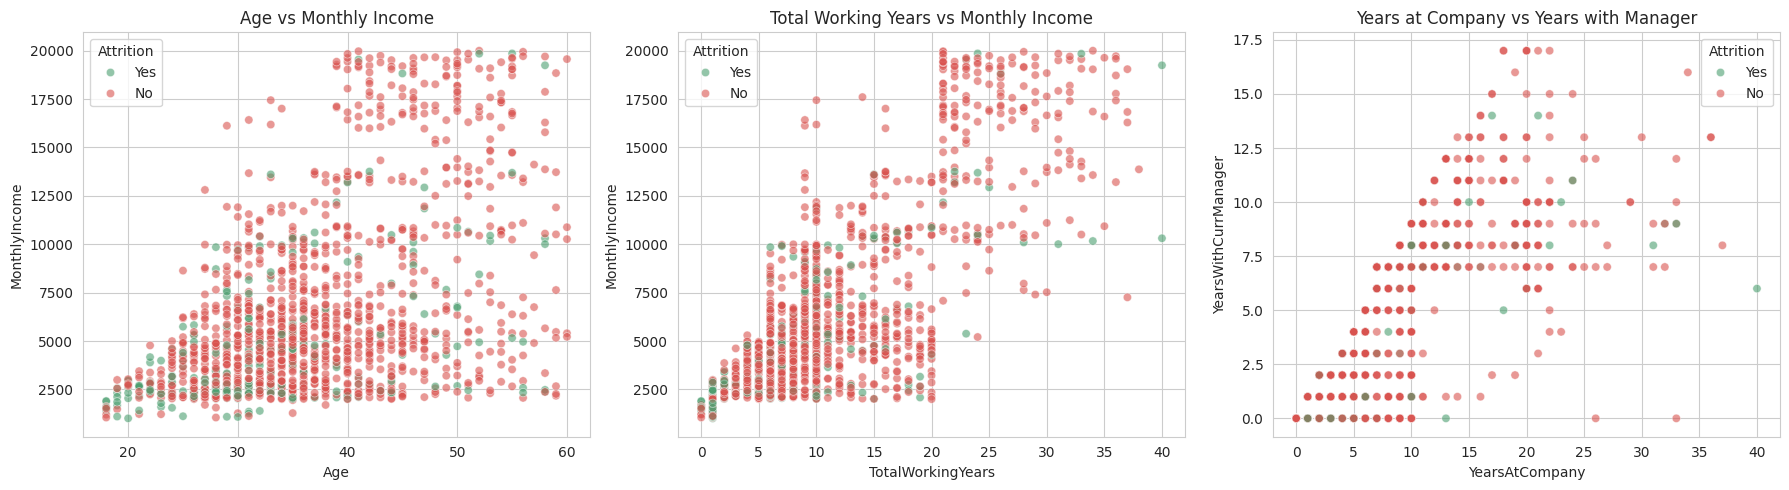

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.scatterplot(x="Age", y="MonthlyIncome", hue="Attrition", data=df, alpha=0.6,
                palette=["#4C9F70", "#D9534F"], ax=axes[0])
axes[0].set_title("Age vs Monthly Income")

sns.scatterplot(x="TotalWorkingYears", y="MonthlyIncome", hue="Attrition", data=df, alpha=0.6,
                palette=["#4C9F70", "#D9534F"], ax=axes[1])
axes[1].set_title("Total Working Years vs Monthly Income")

sns.scatterplot(x="YearsAtCompany", y="YearsWithCurrManager", hue="Attrition", data=df, alpha=0.6,
                palette=["#4C9F70", "#D9534F"], ax=axes[2])
axes[2].set_title("Years at Company vs Years with Manager")
plt.tight_layout()
plt.show()

**Observation:** employees who left have lower median age (32 vs 36), lower median income (about 3,200 vs 5,200) and fewer total working years. MonthlyIncome, YearsAtCompany and TotalWorkingYears have many high outliers (long-serving or senior staff), which are genuine values and not errors, so they were kept. Leavers cluster at the low-income, low-experience end of the scatter plots.

## Step 8: Univariate, bivariate and multivariate analysis

### Univariate analysis
Single variables were already studied in Steps 3 to 5. A quick summary:

In [17]:
print("Mean Age:", round(df["Age"].mean(), 1))
print("Mean vs Median MonthlyIncome:", round(df["MonthlyIncome"].mean()), "vs", round(df["MonthlyIncome"].median()))
print("Mode of JobRole:", df["JobRole"].mode()[0])
print("Std of MonthlyIncome:", round(df["MonthlyIncome"].std()))

Mean Age: 36.9
Mean vs Median MonthlyIncome: 6503 vs 4919
Mode of JobRole: Sales Executive
Std of MonthlyIncome: 4708


### Bivariate analysis: attrition rate by each factor

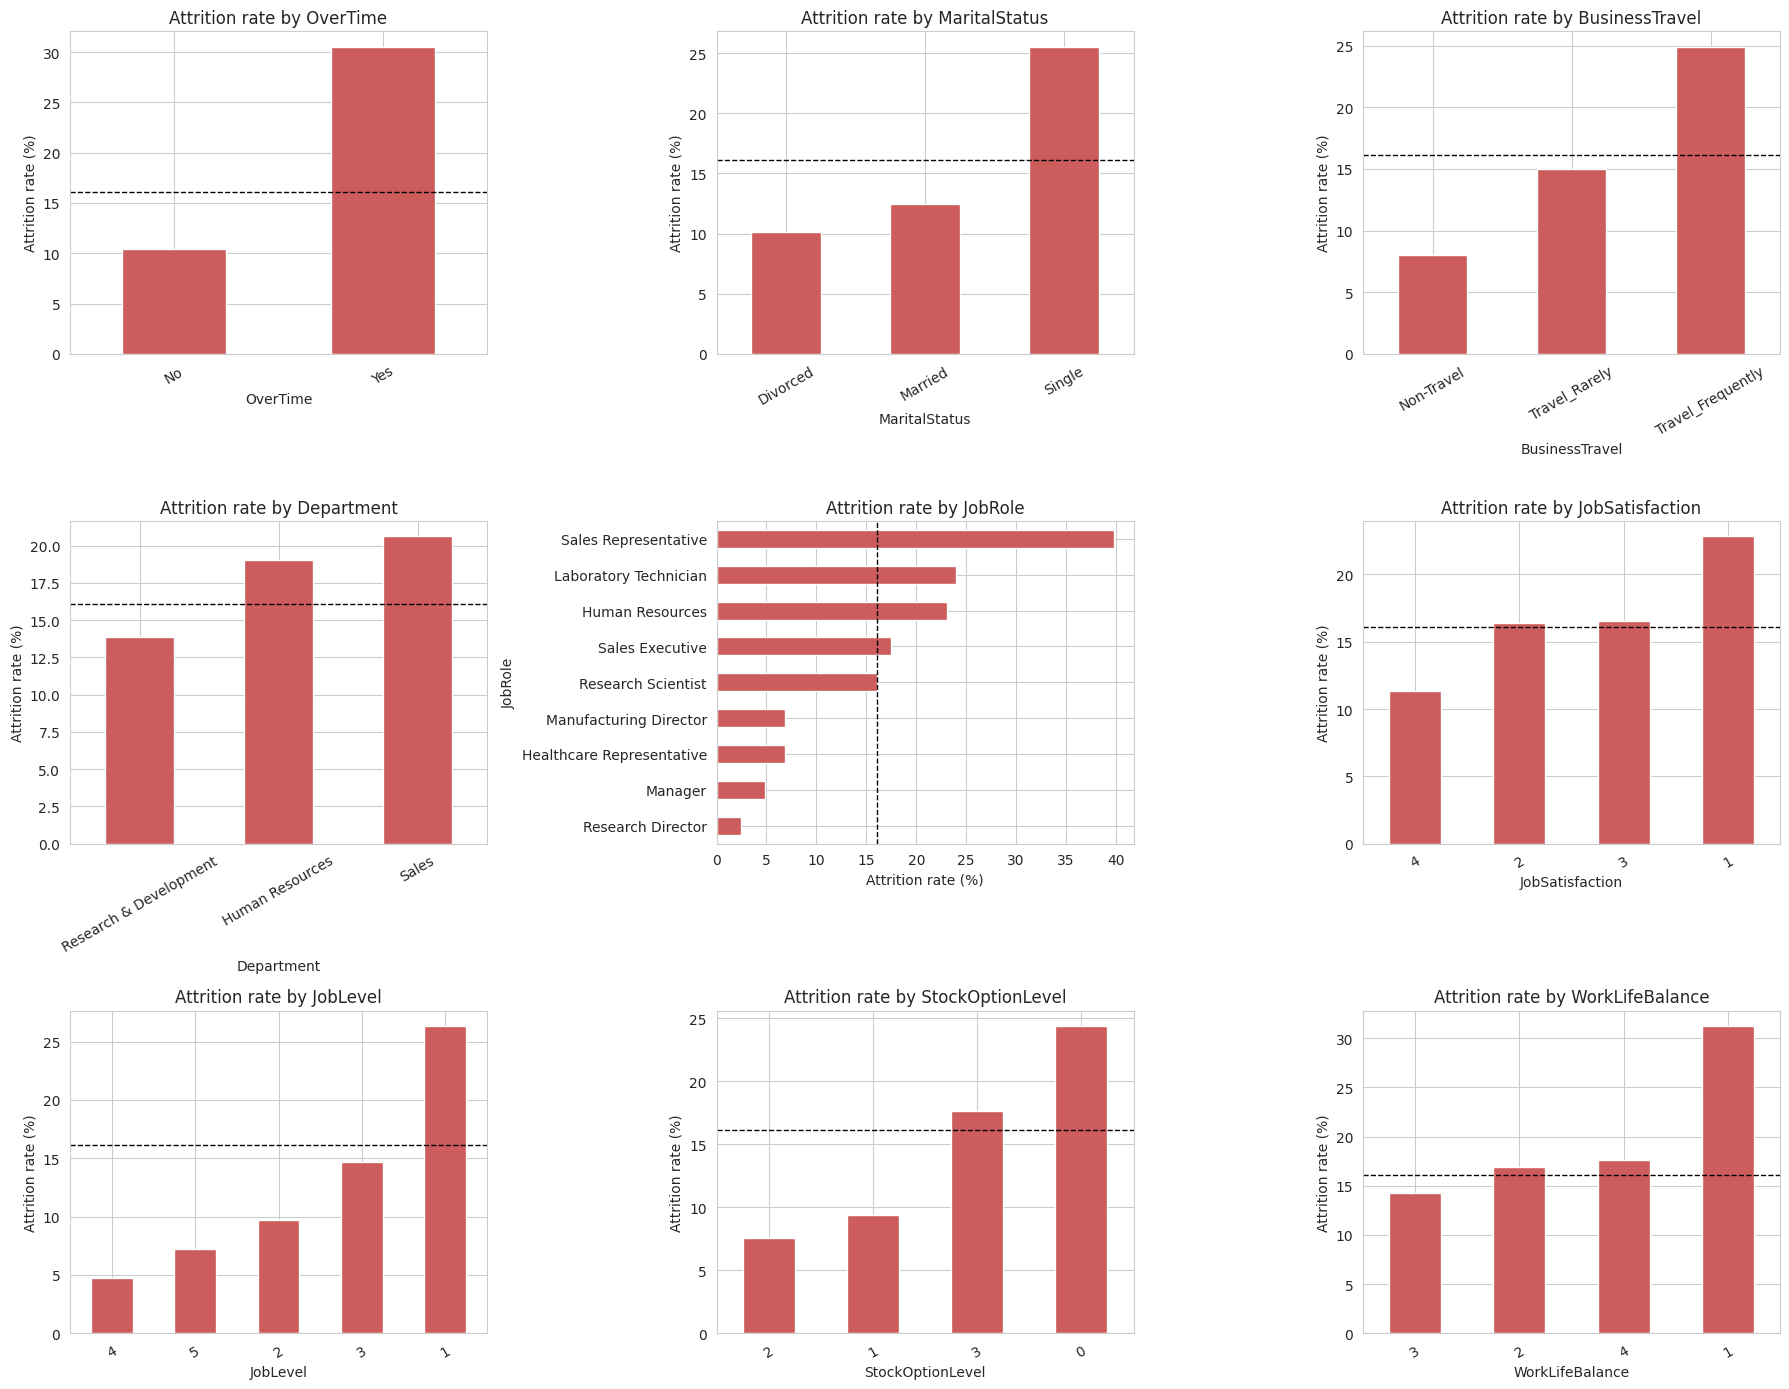

In [18]:
factors = ["OverTime", "MaritalStatus", "BusinessTravel", "Department",
           "JobRole", "JobSatisfaction", "JobLevel", "StockOptionLevel", "WorkLifeBalance"]

fig, axes = plt.subplots(3, 3, figsize=(18, 14))
for ax, col in zip(axes.ravel(), factors):
    rate = df.groupby(col)["AttritionFlag"].mean().mul(100).sort_values()
    if col == "JobRole":
        rate.plot(kind="barh", ax=ax, color="indianred")
        ax.set_xlabel("Attrition rate (%)")
    else:
        rate.plot(kind="bar", ax=ax, color="indianred")
        ax.set_ylabel("Attrition rate (%)")
        ax.tick_params(axis="x", rotation=30)
    ax.axhline(16.1, color="black", linestyle="--", linewidth=1) if col != "JobRole" else ax.axvline(16.1, color="black", linestyle="--", linewidth=1)
    ax.set_title(f"Attrition rate by {col}")
plt.tight_layout()
plt.show()

In [19]:
# Same information as a table (attrition % per category)
for col in ["OverTime", "MaritalStatus", "BusinessTravel", "Department", "JobRole"]:
    print(df.groupby(col)["AttritionFlag"].mean().mul(100).round(1).sort_values(ascending=False), "\n")

OverTime
Yes    30.5
No     10.4
Name: AttritionFlag, dtype: float64 

MaritalStatus
Single      25.5
Married     12.5
Divorced    10.1
Name: AttritionFlag, dtype: float64 

BusinessTravel
Travel_Frequently    24.9
Travel_Rarely        15.0
Non-Travel            8.0
Name: AttritionFlag, dtype: float64 

Department
Sales                     20.6
Human Resources           19.0
Research & Development    13.8
Name: AttritionFlag, dtype: float64 

JobRole
Sales Representative         39.8
Laboratory Technician        23.9
Human Resources              23.1
Sales Executive              17.5
Research Scientist           16.1
Healthcare Representative     6.9
Manufacturing Director        6.9
Manager                       4.9
Research Director             2.5
Name: AttritionFlag, dtype: float64 



In [20]:
# Income band vs attrition
df["IncomeBand"] = pd.qcut(df["MonthlyIncome"], 4, labels=["Low", "Medium", "High", "Very High"])
print(df.groupby("IncomeBand")["AttritionFlag"].mean().mul(100).round(1))

IncomeBand
Low          29.3
Medium       14.2
High         10.6
Very High    10.3
Name: AttritionFlag, dtype: float64


### Multivariate analysis

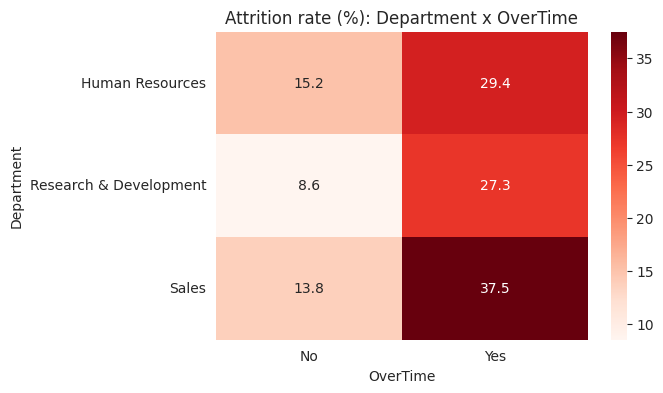

In [21]:
# Attrition rate (%) by Department and OverTime
pt = df.pivot_table(values="AttritionFlag", index="Department", columns="OverTime", aggfunc="mean") * 100
plt.figure(figsize=(6, 4))
sns.heatmap(pt, annot=True, fmt=".1f", cmap="Reds")
plt.title("Attrition rate (%): Department x OverTime")
plt.show()

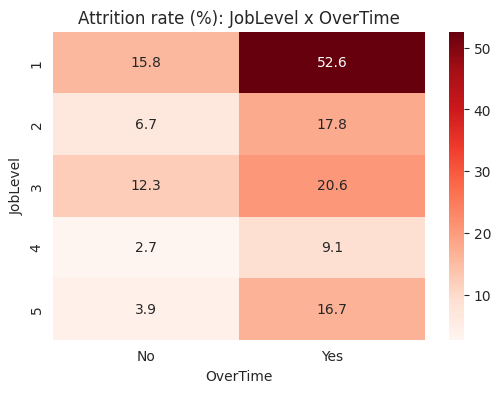

In [22]:
# Attrition rate (%) by Job Level and OverTime
pt2 = df.pivot_table(values="AttritionFlag", index="JobLevel", columns="OverTime", aggfunc="mean") * 100
plt.figure(figsize=(6, 4))
sns.heatmap(pt2, annot=True, fmt=".1f", cmap="Reds")
plt.title("Attrition rate (%): JobLevel x OverTime")
plt.show()

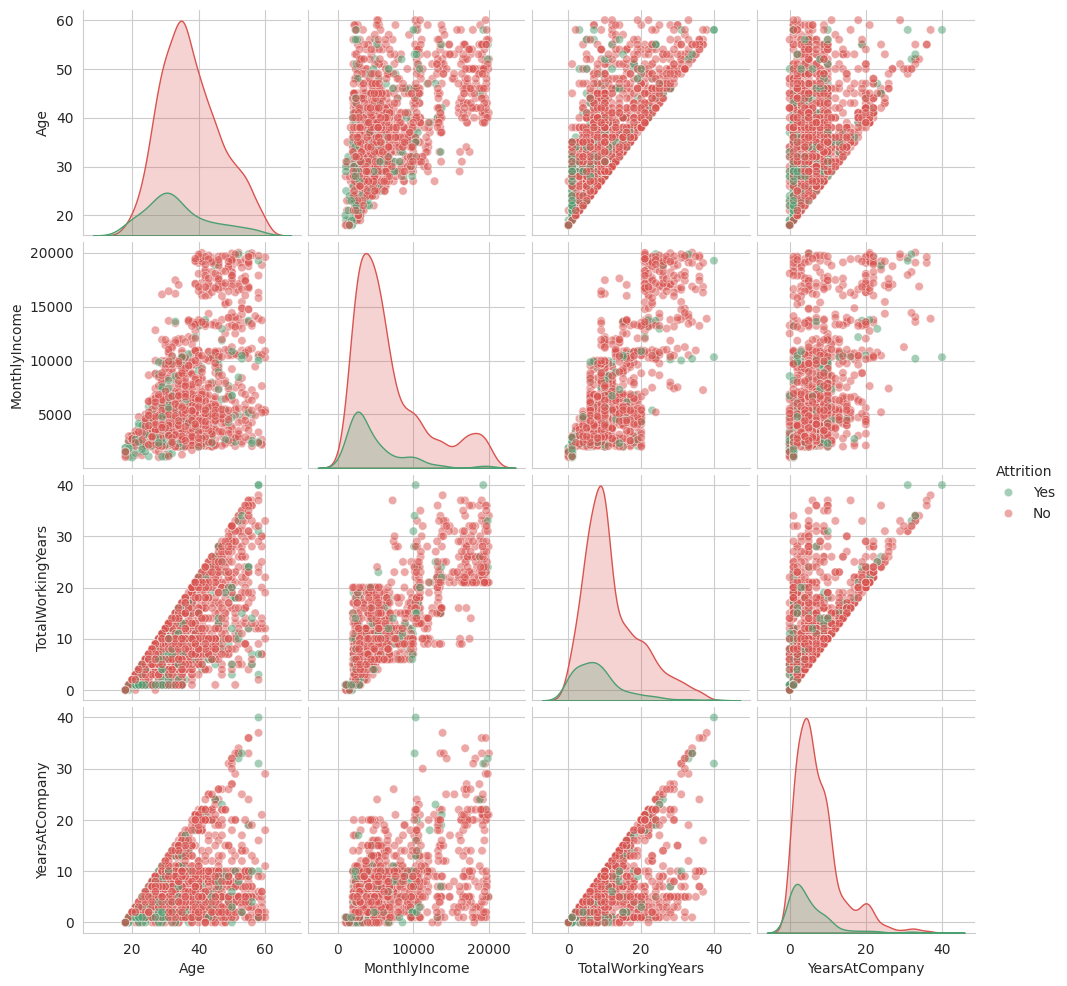

In [23]:
# Pair plot of key numeric features coloured by attrition
sns.pairplot(df[["Age", "MonthlyIncome", "TotalWorkingYears", "YearsAtCompany", "Attrition"]],
             hue="Attrition", palette=["#4C9F70", "#D9534F"], diag_kind="kde", plot_kws={"alpha": 0.5})
plt.show()

## Step 9: Key observations and factors influencing attrition

In [24]:
# Median profile of leavers vs stayers
df.groupby("Attrition")[["Age", "MonthlyIncome", "TotalWorkingYears", "YearsAtCompany",
                         "YearsInCurrentRole", "DistanceFromHome"]].median()

,Age,MonthlyIncome,TotalWorkingYears,YearsAtCompany,YearsInCurrentRole,DistanceFromHome
Attrition,,,,,,
No,36.0,5204.0,10.0,6.0,3.0,7.0
Yes,32.0,3202.0,7.0,3.0,2.0,9.0


In [25]:
# Ranking of categorical factors by gap between highest and lowest attrition rate
rows = []
for col in ["OverTime", "MaritalStatus", "BusinessTravel", "Department", "JobRole",
            "EducationField", "Gender", "JobSatisfaction", "JobLevel", "StockOptionLevel"]:
    r = df.groupby(col)["AttritionFlag"].mean() * 100
    rows.append((col, round(r.max() - r.min(), 1), r.idxmax(), round(r.max(), 1)))
pd.DataFrame(rows, columns=["Factor", "Gap (% points)", "Highest-risk group", "Attrition % there"]) \
  .sort_values("Gap (% points)", ascending=False).reset_index(drop=True)

,Factor,Gap (% points),Highest-risk group,Attrition % there
0,JobRole,37.3,Sales Representative,39.8
1,JobLevel,21.6,1,26.3
2,OverTime,20.1,Yes,30.5
3,BusinessTravel,16.9,Travel_Frequently,24.9
4,StockOptionLevel,16.8,0,24.4
5,MaritalStatus,15.4,Single,25.5
6,EducationField,12.5,Human Resources,25.9
7,JobSatisfaction,11.5,1,22.8
8,Department,6.8,Sales,20.6
9,Gender,2.2,Male,17.0


## Step 10: Report — findings and recommendations

### Dataset overview
The IBM HR dataset has 1470 employees and 35 columns (31 after removing 4 uninformative ones, plus one derived flag). There are no missing values or duplicates. The target `Attrition` is imbalanced: **237 employees (16.1%) left** and 1233 stayed.

### Key findings
1. **Overtime is the strongest single driver.** 30.5% of employees working overtime left, compared with 10.4% of those who do not (about 3 times higher).
2. **Role and level:** Sales Representatives have the highest attrition (39.8%), followed by Laboratory Technicians (23.9%) and HR staff (23.1%). Research Directors (2.5%) and Managers (4.9%) rarely leave. Entry-level employees (Job Level 1) leave far more (26.3%) than higher levels.
3. **Pay and experience:** leavers have a lower median income (about 3,200 vs 5,200), lower median age (32 vs 36) and fewer working years. Younger, early-career, lower-paid employees are the most likely to leave.
4. **Marital status:** single employees leave at 25.5%, against 12.5% for married and 10.1% for divorced.
5. **Business travel:** frequent travellers leave at 24.9%, compared with 8.0% for non-travellers.
6. **Satisfaction:** employees with the lowest job satisfaction leave at 22.8%, about double the rate of the most satisfied (11.3%).
7. **Department:** Sales (20.6%) and HR (19.0%) have higher attrition than R&D (13.8%).
8. **Gender** makes only a small difference (female 14.8%, male 17.0%).
9. **Data quality notes:** income and tenure variables are right-skewed with genuine high outliers. JobLevel, MonthlyIncome and TotalWorkingYears are highly correlated (redundant), as are PerformanceRating and PercentSalaryHike.

### Recommendations
- **Reduce overtime** through workload balancing, hiring or rotation, especially in high-risk roles.
- **Review pay and career paths for entry-level and Sales Representative roles:** market-aligned salaries, stock options and clear promotion routes.
- **Target retention programmes at young, single, early-career employees:** mentoring, engagement activities and development plans.
- **Limit frequent travel** or compensate it with flexibility and allowances.
- **Run regular satisfaction surveys** and act on low scores, since they are an early warning sign.
- **For future modelling:** handle the class imbalance (SMOTE or class weights), remove redundant correlated features, and use skew-friendly transformations or scaling.

### Conclusion
EDA showed that attrition is not caused by a single variable but by a combination of overtime, low job level and income, early career stage, frequent travel and low satisfaction. These insights help HR focus retention efforts on the highest-risk groups and prepare the data for a predictive model in the next experiment.

# Questions and Answers

### Q1. What is Exploratory Data Analysis (EDA), and why is it performed before machine learning?

**EDA** is the process of examining a dataset using descriptive statistics and visualizations to understand its structure, distributions, patterns, relationships and problems, before any formal modelling. It was popularized by John Tukey.

**Why it is done before machine learning:**
- It shows what the data looks like (types, ranges, distributions), so suitable algorithms and preprocessing can be chosen.
- It reveals data quality problems such as missing values, duplicates, outliers and wrong values.
- It detects class imbalance and skewness (for example, only 16% attrition in the HR dataset).
- It uncovers relationships and redundant features, which guides feature selection and engineering.
- It helps form hypotheses and checks assumptions of the model (for example, linearity or normality).
- It prevents building models on misunderstood or faulty data, saving time and avoiding wrong conclusions.

### Q2. Differentiate between univariate, bivariate, and multivariate analysis with suitable examples.

| Basis | Univariate | Bivariate | Multivariate |
|---|---|---|---|
| Variables analysed | One | Two | Three or more |
| Purpose | Describe one variable: centre, spread, shape | Study the relationship between two variables | Study interactions among several variables together |
| Techniques | Mean, median, mode, std, histogram, box plot, count plot | Scatter plot, correlation, grouped bar chart, cross-tabulation | Correlation heatmap, pair plot, pivot-table heatmap, regression, PCA |
| HR example | Distribution of `Age`, or count of employees per `Department` | `OverTime` vs `Attrition` (30.5% vs 10.4%), `Age` vs `MonthlyIncome` | Attrition rate by `Department` and `OverTime` together; pair plot of Age, Income, Experience coloured by Attrition |

### Q3. What insights can be obtained from a correlation heatmap?

A correlation heatmap shows the correlation coefficient (-1 to +1) between every pair of numerical variables using colours. It helps to:
- find **strong positive** relationships (for example, `MonthlyIncome` and `JobLevel` about 0.95) and **strong negative** relationships;
- detect **multicollinearity** (highly correlated, redundant features) so some can be removed;
- identify which features are most related to the **target variable**, to guide feature selection;
- spot features with **near-zero correlation** that may add little information;
- get a quick overview of the whole dataset's structure in one picture.

Limitation: Pearson correlation only captures linear relationships between numerical variables.

### Q4. Explain the purpose of histograms, box plots, and scatter plots in EDA.

- **Histogram:** shows the distribution of a single numerical variable by grouping values into bins. It reveals shape (normal, skewed, bimodal), central tendency, spread and gaps. Example: `MonthlyIncome` is right-skewed.
- **Box plot:** summarizes a variable with its median, quartiles (Q1, Q3), IQR and whiskers, and displays outliers as points. It is also used to compare a numerical variable across categories. Example: `MonthlyIncome` for employees who left vs stayed.
- **Scatter plot:** plots two numerical variables against each other to show the direction, strength and shape of their relationship, and to spot clusters and outliers. Example: `Age` vs `MonthlyIncome`.

### Q5. How can EDA help identify data quality issues before analysis?

- **Missing values:** `isnull().sum()` and missing-value heatmaps show which columns have gaps and how many.
- **Duplicates:** `duplicated().sum()` reveals repeated records.
- **Outliers and errors:** box plots, scatter plots and the IQR method expose extreme or impossible values (for example, age = 200).
- **Wrong data types and inconsistent formats:** `info()` and `value_counts()` show numbers stored as text, or inconsistent labels such as "Male", "male", "M".
- **Constant or useless columns:** `describe()` shows columns with the same value for every row (such as `EmployeeCount` and `StandardHours` in the HR data).
- **Skewness and class imbalance:** histograms and target counts show distribution problems that affect modelling.
- **Impossible relationships:** scatter plots and cross-tabs expose logical inconsistencies, such as years at company greater than total working years.

### Q6. Why is correlation important in predictive analytics? Can correlation imply causation?

**Importance of correlation:**
- It identifies features related to the target, so useful predictors can be selected.
- It detects multicollinearity between predictors, which makes models like linear regression unstable.
- It helps reduce dimensionality by removing redundant features.
- It gives a quick, first indication of which relationships are worth modelling.

**Correlation does not imply causation.** Two variables can move together without one causing the other, because of a hidden third variable (confounder) or coincidence. Example: ice-cream sales and drowning incidents are correlated, but hot weather causes both. In the HR data, `DistanceFromHome` is slightly positively correlated with attrition, but this alone does not prove that distance causes people to leave. Establishing causation needs controlled experiments, A/B tests or causal inference methods.

### Q7. Which visualization would you use to analyze categorical and numerical variables? Justify your choice.

| Analysis | Visualization | Justification |
|---|---|---|
| One categorical variable | Count plot / bar chart (pie chart for few categories) | Shows frequency of each category and the most common ones |
| One numerical variable | Histogram with density (KDE) plot, box plot | Shows distribution, skewness, spread and outliers |
| Categorical vs categorical | Grouped / stacked bar chart, heatmap of cross-tab | Compares proportions across groups (for example, attrition rate by `OverTime`) |
| Categorical vs numerical | Box plot, violin plot, bar chart of group means | Compares the distribution of a number across categories (for example, `MonthlyIncome` by `Attrition`) |
| Numerical vs numerical | Scatter plot, correlation heatmap | Shows relationship, trend and correlation strength |

### Q8. What business insights can be derived from the Netflix (or Superstore/HR Analytics) dataset through EDA?

**HR Analytics (IBM Employee Attrition) dataset, as used in this experiment:**
- Overall attrition is 16.1%, so the target is imbalanced.
- **Overtime** is the strongest driver: 30.5% attrition with overtime vs 10.4% without.
- **Sales Representatives** have the highest attrition (39.8%), while Research Directors have the lowest (2.5%).
- Single employees (25.5%) and frequent travellers (24.9%) leave more.
- Leavers have lower median income (about 3,200 vs 5,200) and are younger (median 32 vs 36). Entry-level employees (Job Level 1) leave far more than higher levels.
- Lower job satisfaction goes with higher attrition (22.8% at the lowest level vs 11.3% at the highest).

**Business actions:** reduce overtime, improve pay and career paths for entry-level and sales roles, target retention programmes at young and early-career staff, limit travel or compensate it, and monitor satisfaction regularly.

(For Superstore data, EDA would show top-selling categories, profitable and loss-making products or regions, the effect of discounts on profit, and seasonal sales trends. For Netflix data, it would show the movies vs TV shows split, content growth by year, top genres and countries, and typical durations.)

### Q9. How does EDA contribute to feature selection and model building?

- **Feature selection:** correlation analysis and group comparisons show which features relate to the target (for example, `OverTime`, `JobRole`, `MonthlyIncome`) and which do not (for example, `PerformanceRating`, `HourlyRate`, almost no relation to attrition).
- **Removing redundancy:** highly correlated features (`MonthlyIncome` and `JobLevel`) can be dropped to avoid multicollinearity. Constant or ID columns are removed.
- **Feature engineering:** patterns seen in plots suggest new features, such as income bands, age groups or tenure ratios.
- **Choosing preprocessing:** skewness suggests log transformation, outliers suggest capping, categorical columns suggest an encoding method, and different scales suggest scaling.
- **Choosing the model and metric:** class imbalance suggests class weights/SMOTE and metrics like F1 or recall instead of accuracy; non-linear patterns suggest tree-based models rather than linear ones.
- **Validating assumptions:** checks of linearity, normality and outliers show whether a chosen model is appropriate.

### Q10. What challenges might arise while performing EDA on large-scale real-world datasets?

- **Volume and performance:** very large data may not fit in memory, and plots or computations become slow (solutions: sampling, chunking, Dask or Spark).
- **High dimensionality:** hundreds of features make heatmaps and pair plots unreadable and complicate feature selection.
- **Data quality problems:** many missing values, duplicates, inconsistent formats and noise across multiple sources.
- **Overplotting:** millions of points in a scatter plot hide patterns (use sampling, hexbin plots or density plots).
- **Mixed data types:** combining numerical, categorical, text, date and geographic data needs different techniques.
- **Imbalance and bias:** rare classes and unrepresentative samples can give misleading conclusions.
- **Misinterpretation:** spurious correlations appear easily in large data, and correlation can be mistaken for causation.
- **Data privacy and access:** sensitive data may restrict how it can be explored.
- **Streaming or changing data:** patterns may change over time, so EDA has to be repeated.